# 02 · EDA textual e preparação do texto

O notebook 01 decidiu o grão e os metadados. Este olha para o texto que vai ser indexado: quanto dele sobra depois da limpeza, se os documentos cabem inteiros no modelo de embeddings, o que se repete, que palavras separam clientes satisfeitos de insatisfeitos e o que isso implica para a recuperação.

O pré-processamento está em `src/preprocessing/` e gera `data/processed/documentos.parquet` (`make documentos`), com o texto em três versões: original para exibição, limpo para os embeddings e o contexto do LLM, normalizado para a deduplicação e o índice lexical.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from src.preprocessing.limpeza import normalize
from src.preprocessing.tokenizacao import stopwords
from src.visualization.estilo import BLUE, GRAY, GREEN, ORANGE, RED, SCORE_COLORS, apply_style, fmt_pct, save

apply_style()
warnings.filterwarnings("ignore")
os.environ["TQDM_DISABLE"] = "1"
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 180)

base = pd.read_parquet("data/processed/avaliacoes.parquet")
docs = pd.read_parquet("data/processed/documentos.parquet")
milhar = lambda n: f"{n:,}".replace(",", ".")
print(milhar(len(base)), "avaliações |", milhar(len(docs)), "documentos |", milhar(docs["doc_id"].nunique()), "textos distintos")

98.410 avaliações | 42.093 documentos | 34.889 textos distintos


## 1. Do texto bruto ao documento

Entram no índice as avaliações com título ou comentário. A tabela mostra o funil e, em seguida, o que ficou de fora.

In [2]:
com_texto = base["has_comment"] | base["has_title"]
funil = pd.Series({
    "avaliações": len(base),
    "com título ou comentário": int(com_texto.sum()),
    "  ...só com título": int((base["has_title"] & ~base["has_comment"]).sum()),
    "fora do índice (sem palavra útil depois da limpeza)": int(com_texto.sum() - len(docs)),
    "documentos (avaliações no índice)": len(docs),
    "textos distintos (entradas do índice)": docs["doc_id"].nunique(),
})
funil.to_frame("quantidade")

,quantidade
avaliações,98410
com título ou comentário,42370
...só com título,1729
fora do índice (sem palavra útil depois da limpeza),277
documentos (avaliações no índice),42093
textos distintos (entradas do índice),34889


In [3]:
fora = base[com_texto & ~base["review_id"].isin(docs["review_id"])]
exemplos = (fora["review_comment_title"].fillna("") + " " + fora["review_comment_message"].fillna("")).str.strip()
exemplos.map(lambda s: s.encode("ascii", "ignore").decode() or "(só emoji)").value_counts().head(12)

10            54
.             42
(só emoji)    14
*****         12
9             10
...            9
5              8
. .            8
8              8
10 10          6
..             5
A              4
Name: count, dtype: int64[pyarrow]

- 42.370 avaliações têm algum texto, e 1.729 delas só título. **Os títulos sem comentário entram (D21):** são escritos pelo cliente como o comentário e, embora quase sempre genéricos ("ótimo", "recomendo"), contam como evidência de satisfação; depois da deduplicação eles se juntam aos grupos de texto igual.
- 277 ficam fora porque, depois da limpeza, não sobra palavra útil: notas escritas como número ("10", "9", "5"), pontuação, asteriscos e emojis soltos. Não há o que recuperar por semântica nem por termo.
- As 42.093 avaliações restantes viram 34.889 textos distintos, que são as entradas do índice.

### Tamanho e fragmentação

O modelo de embeddings previsto no plano (`paraphrase-multilingual-MiniLM-L12-v2`, o mesmo das aulas) lê no máximo 128 tokens; o que passa disso é truncado. O tamanho dos documentos é medido com o tokenizador do próprio modelo.

In [4]:
from transformers import AutoTokenizer

MODEL = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
tokenizer = AutoTokenizer.from_pretrained(MODEL)
docs["n_wordpieces"] = [len(ids) for ids in tokenizer(docs["text_clean"].tolist())["input_ids"]]
tamanho = docs[["n_chars", "n_words", "n_wordpieces"]].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(1)
tamanho.columns = ["caracteres", "palavras", "tokens do modelo"]
tamanho

,caracteres,palavras,tokens do modelo
count,42093.0,42093.0,42093.0
mean,69.2,11.8,18.9
std,54.6,9.7,13.8
min,2.0,1.0,3.0
25%,28.0,4.0,8.0
50%,54.0,9.0,15.0
75%,96.0,16.0,25.0
95%,193.0,33.0,48.0
99%,209.1,38.0,57.0
max,229.0,48.0,186.0


In [5]:
LIMITE = 128  # tamanho máximo de entrada do modelo de embeddings, em tokens
print("documentos acima do limite:", int((docs["n_wordpieces"] > LIMITE).sum()))
docs.loc[docs["n_wordpieces"] > LIMITE, ["n_chars", "n_wordpieces", "text_clean"]]

documentos acima do limite: 1


,n_chars,n_wordpieces,text_clean
20216,209,186,"excelente. muito bom, recomendo.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,...."


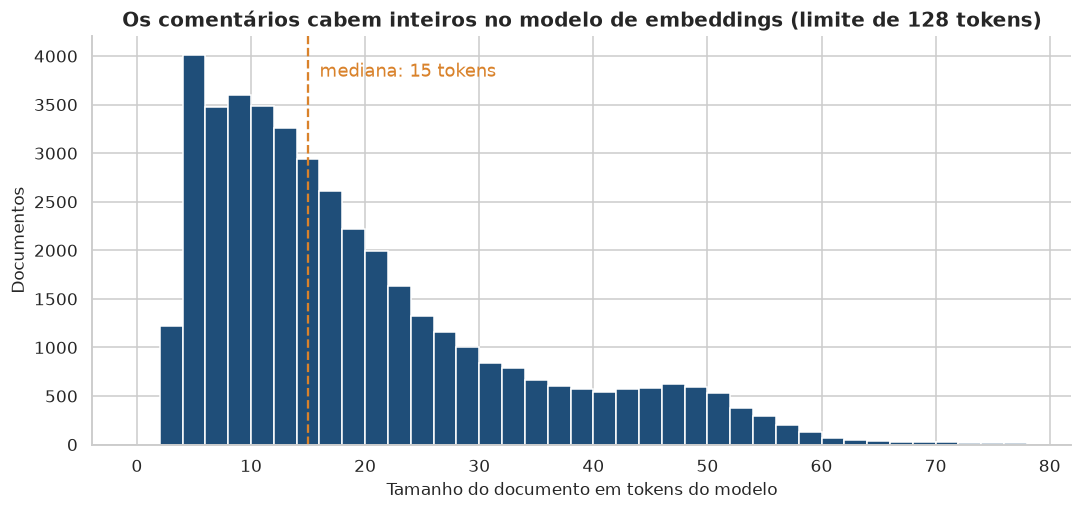

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.hist(docs["n_wordpieces"], bins=range(0, 80, 2), color=BLUE)
med = docs["n_wordpieces"].median()
ax.axvline(med, color=ORANGE, ls="--")
ax.text(med + 1, ax.get_ylim()[1] * 0.9, f"mediana: {med:.0f} tokens", color=ORANGE)
ax.set(title="Os comentários cabem inteiros no modelo de embeddings (limite de 128 tokens)",
       xlabel="Tamanho do documento em tokens do modelo", ylabel="Documentos")
save(fig, "02_tamanho_documentos");

**Decisão D01: um documento por avaliação, sem fragmentação.** O documento mediano tem 54 caracteres e 15 tokens do modelo; o percentil 99 fica em 57 tokens, menos da metade do limite. Só um documento passa de 128 tokens, e o excesso é uma sequência de pontuação (",.,.,.") depois de "excelente. muito bom, recomendo", que o truncamento descarta sem perda. Fragmentar textos desse tamanho só separaria a reclamação do motivo. O chunking que a aula apresenta para documentos longos não se aplica a esta base.

### HT1. Comentários negativos são mais longos

Teste: Mann-Whitney unilateral do número de palavras entre notas 1 e 2 e notas 4 e 5.

In [7]:
por_nota = docs.groupby("review_score")["n_words"].agg(["count", "median", "mean"]).round(1)
neg_w = docs.loc[docs["review_score"] <= 2, "n_words"]
pos_w = docs.loc[docs["review_score"] >= 4, "n_words"]
u, p = stats.mannwhitneyu(neg_w, pos_w, alternative="greater")
r_rb = 2 * u / (len(neg_w) * len(pos_w)) - 1
rho = stats.spearmanr(docs["review_score"], docs["n_words"])
print(f"Mann-Whitney (notas 1-2 > notas 4-5): U = {u:,.0f}, p = {p:.1e}, correlação bisserial de postos = {r_rb:.3f}")
print(f"Spearman nota x palavras: {rho.statistic:.3f}")
por_nota

Mann-Whitney (notas 1-2 > notas 4-5): U = 226,262,621, p = 0.0e+00, correlação bisserial de postos = 0.510
Spearman nota x palavras: -0.381


,count,median,mean
review_score,,,
1,8704,16.0,17.9
2,2133,16.0,17.6
3,3594,13.0,14.8
4,6173,8.0,10.6
5,21489,7.0,8.5


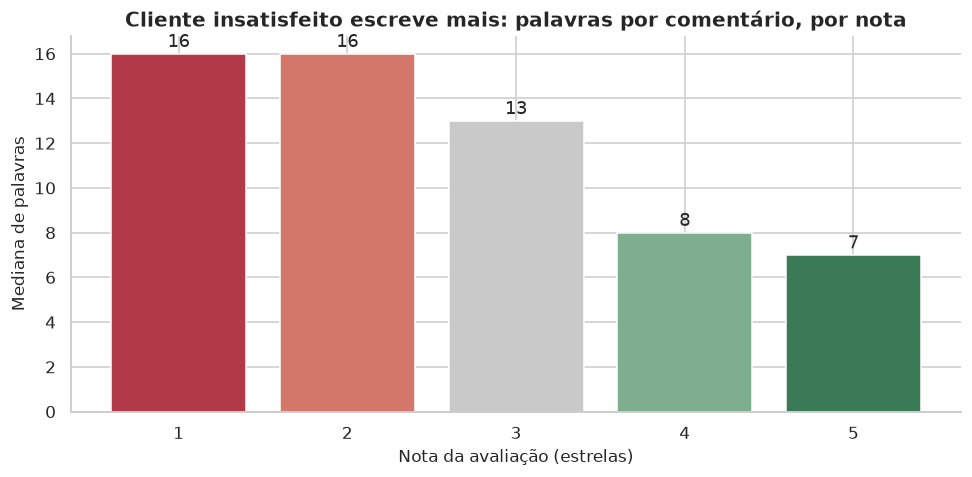

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(por_nota.index.astype(str), por_nota["median"], color=[SCORE_COLORS[n] for n in por_nota.index])
for i, v in enumerate(por_nota["median"]):
    ax.text(i, v + 0.3, f"{v:.0f}", ha="center", fontsize=12)
ax.set(title="Cliente insatisfeito escreve mais: palavras por comentário, por nota",
       xlabel="Nota da avaliação (estrelas)", ylabel="Mediana de palavras")
save(fig, "02_palavras_por_nota");

**HT1 confirmada, com efeito grande (correlação bisserial de postos = 0,51).** A mediana é de 16 palavras nas notas 1 e 2 e de 7 a 8 nas notas 4 e 5 (Spearman entre nota e tamanho = -0,38). O cliente insatisfeito explica o que aconteceu; o satisfeito confirma em poucas palavras.

**Para o RAG:** as evidências de reclamação trazem detalhe (motivo, prazo, pedido de reembolso), enquanto os elogios são curtos e repetitivos. Nas perguntas sobre elogios, a contagem de textos iguais diz mais que os textos em si, o que motiva a deduplicação com contagem.

### Textos repetidos

In [9]:
grupos = docs.drop_duplicates("doc_id")
rep = grupos[grupos["doc_size"] > 1]
dup = pd.Series({
    "textos repetidos (grupos com mais de uma avaliação)": len(rep),
    "avaliações dentro desses grupos": int(rep["doc_size"].sum()),
    "% das avaliações com texto": round(100 * rep["doc_size"].sum() / len(docs), 1),
    "mediana de caracteres dos textos repetidos": rep["n_chars"].median(),
    "maior texto repetido (caracteres)": rep["n_chars"].max(),
})
print(dup.to_string())
top = docs[docs["is_representative"]].nlargest(15, "doc_size")
top.assign(nota_media=top["doc_id"].map(docs.groupby("doc_id")["review_score"].mean().round(2)))[
    ["text_norm", "doc_size", "nota_media"]]

textos repetidos (grupos com mais de uma avaliação)    1026.0
avaliações dentro desses grupos                        8230.0
% das avaliações com texto                               19.6
mediana de caracteres dos textos repetidos               22.0
maior texto repetido (caracteres)                       122.0


,text_norm,doc_size,nota_media
31761,otimo,558,4.83
29174,muito bom,555,4.69
37494,recomendo,420,4.62
574,bom,405,4.18
22909,excelente,266,4.87
17461,super recomendo,153,4.87
11846,otimo produto,138,4.85
34927,ok,130,4.45
27858,otima,120,4.82
16123,boa,118,4.17


In [10]:
por_doc = docs.groupby("doc_id").agg(n=("review_id", "size"), notas=("review_score", "nunique"),
                                     categorias=("main_category", "nunique"))
multi = por_doc[por_doc["n"] > 1]
print(f"grupos repetidos com mais de uma nota: {(multi['notas'] > 1).mean():.0%}")
print(f"grupos repetidos com mais de uma categoria: {(multi['categorias'] > 1).mean():.0%}")

grupos repetidos com mais de uma nota: 51%
grupos repetidos com mais de uma categoria: 93%


**Decisão D04: textos idênticos depois de normalizados viram uma entrada do índice, com a contagem.** 1.026 textos se repetem e cobrem 8.230 avaliações (19,6% das que têm texto). São curtos: mediana de 22 caracteres, e o maior tem 122. "Ótimo" (558 avaliações), "muito bom" (555) e "recomendo" (420) lideram; "não recebi o produto" aparece 107 vezes, com nota média 1,24. Sem a deduplicação, uma pergunta sobre elogios devolveria várias cópias de "ótimo" no top-10.

O grupo, porém, não é homogêneo: 51% dos textos repetidos aparecem com mais de uma nota e 93% com mais de uma categoria. Por isso o índice guarda um texto por grupo, mas o filtro por metadado é aplicado por avaliação: numa pergunta sobre uma categoria, o grupo entra se alguma avaliação dele for da categoria, e a contagem exibida é a das avaliações que passaram no filtro.

## 2. Termos que separam notas baixas e altas

TF-IDF sobre o texto normalizado, sem stopwords (com as negações mantidas, D22) e com termos presentes em pelo menos 20 comentários. O qui-quadrado entre cada termo e o grupo (notas 1 e 2 contra notas 4 e 5; a nota 3 fica de fora) ordena os termos que mais separam os grupos. As colunas de % mostram em quantos comentários de cada grupo o termo aparece, o que é mais fácil de ler que o peso TF-IDF.

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import chi2

polar = docs[docs["review_score"] != 3].copy()
polar["negativa"] = (polar["review_score"] <= 2).astype(int)
print(polar["negativa"].value_counts().rename({1: "notas 1 e 2", 0: "notas 4 e 5"}).to_string())

vec = TfidfVectorizer(stop_words=sorted(stopwords()), min_df=20, token_pattern=r"(?u)\b[a-z][a-z0-9]+\b")
X = vec.fit_transform(polar["text_norm"])
termos = np.array(vec.get_feature_names_out())
chi, pval = chi2(X, polar["negativa"])
media_neg = np.asarray(X[polar["negativa"].to_numpy() == 1].mean(axis=0)).ravel()
media_pos = np.asarray(X[polar["negativa"].to_numpy() == 0].mean(axis=0)).ravel()
df_neg = np.asarray((X[polar["negativa"].to_numpy() == 1] > 0).mean(axis=0)).ravel()
df_pos = np.asarray((X[polar["negativa"].to_numpy() == 0] > 0).mean(axis=0)).ravel()
rank = pd.DataFrame({"termo": termos, "qui2": chi, "tfidf_neg": media_neg, "tfidf_pos": media_pos,
                     "pct_docs_neg": 100 * df_neg, "pct_docs_pos": 100 * df_pos})
rank["lado"] = np.where(rank["tfidf_neg"] > rank["tfidf_pos"], "negativo", "positivo")
print(f"vocabulário com min_df=20: {len(termos):,} termos".replace(",", "."))

negativa
notas 4 e 5    27662
notas 1 e 2    10837


vocabulário com min_df=20: 1.212 termos


In [12]:
top_neg = rank[rank["lado"] == "negativo"].nlargest(20, "qui2")
top_pos = rank[rank["lado"] == "positivo"].nlargest(20, "qui2")
pd.concat([top_neg.reset_index(drop=True)[["termo", "pct_docs_neg", "pct_docs_pos"]].round(1),
           top_pos.reset_index(drop=True)[["termo", "pct_docs_pos", "pct_docs_neg"]].round(1)],
          axis=1, keys=["mais associados às notas 1 e 2", "mais associados às notas 4 e 5"])

mais associados às notas 1 e 2                           mais associados às notas 4 e 5                          
                            termo pct_docs_neg pct_docs_pos                          termo pct_docs_pos pct_docs_neg
0                             nao         60.6          6.7                            bom         17.4          2.1
1                          recebi         28.4          5.2                          otimo         11.8          0.2
2                         comprei         16.3          2.0                      recomendo         19.7          4.7
3                           ainda         12.3          2.3                          antes         19.1          1.7
4                      aguardando          4.0          0.2                      excelente          8.2          0.1
5                           agora          6.1          0.6                          prazo         25.4          8.0
6                           quero          4.5          0.2                          super          8.5          0.6
7                             nem          4.3          0.3                         rapida          6.2          0.2
8                         pessima          2.4          0.0                           tudo          7.9          1.0
9                         contato          4.2          0.2                          otima          4.9          0.1
10                           dois          4.1          0.4                            bem          9.2          1.8
11                         apenas          4.8          0.5                       perfeito          3.7          0.1
12                         errado          3.1          0.2                       parabens          3.9          0.1
13                        momento          3.4          0.2                         rapido          4.2          0.5
14                        pessimo          2.4          0.0                         adorei          2.9          0.1
15                       resposta          3.0          0.1                            boa          4.4          1.5
16                       dinheiro          2.8          0.0                             ok          2.6          0.3
17                        aguardo          2.8          0.1                           amei          2.7          0.0
18                           ruim          2.2          0.1                     satisfeito          2.3          0.2
19                         paguei          3.1          0.2                         gostei          5.4          2.5

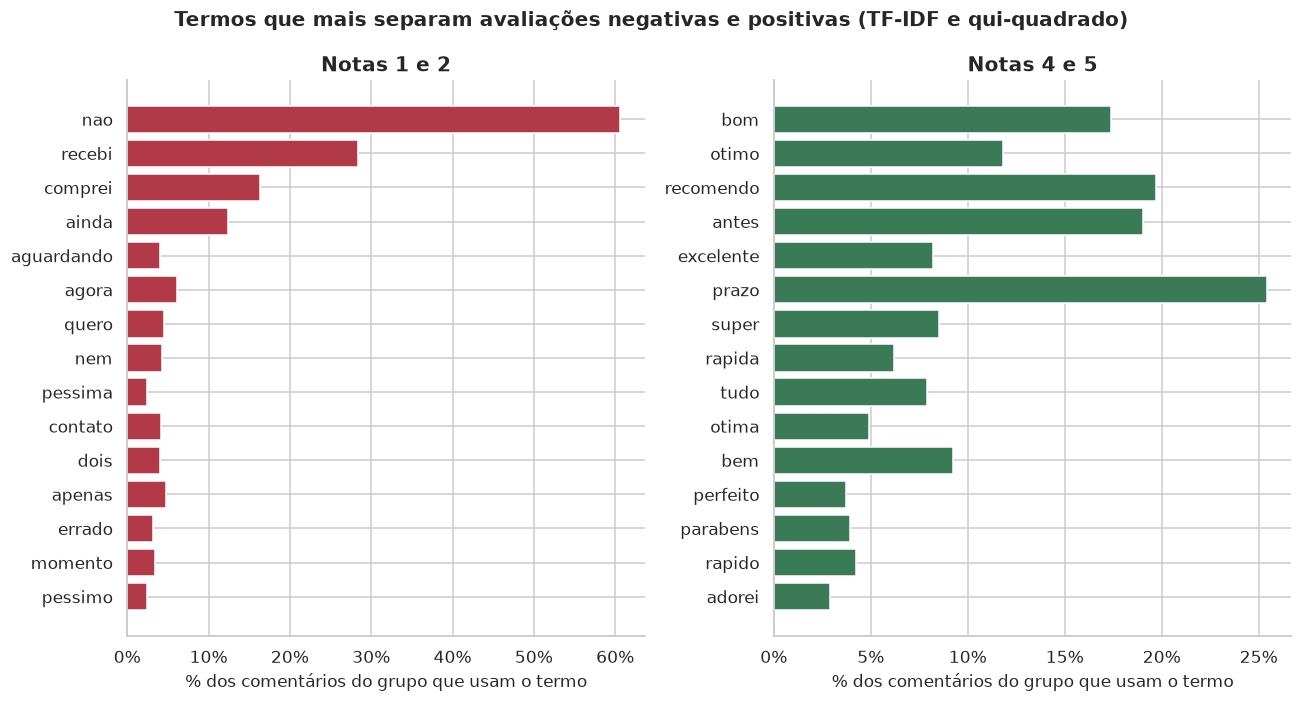

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6.5))
for ax, top, cor, titulo in [(axes[0], top_neg.head(15), RED, "Notas 1 e 2"),
                             (axes[1], top_pos.head(15), GREEN, "Notas 4 e 5")]:
    col = "pct_docs_neg" if cor == RED else "pct_docs_pos"
    ax.barh(top["termo"][::-1], top[col][::-1], color=cor)
    ax.set(title=titulo, xlabel="% dos comentários do grupo que usam o termo")
    fmt_pct(ax, "x")
fig.suptitle("Termos que mais separam avaliações negativas e positivas (TF-IDF e qui-quadrado)",
             fontweight="bold", fontsize=13)
save(fig, "02_termos_por_nota");

Os termos negativos descrevem o processo de compra mais do que o produto. "Não" está em 61% dos comentários de nota 1 e 2 (contra 7% nos de 4 e 5), "recebi" em 28%, e logo depois vêm "ainda", "aguardando", "agora", "quero", "contato", "resposta", "dinheiro" e "paguei": é o vocabulário de quem espera um pedido e tenta falar com a loja. "Errado", "péssimo" e "ruim" aparecem, mas cada um em 2% a 3% dos comentários negativos. Os termos positivos são elogios curtos ("bom", "ótimo", "recomendo", "excelente") e, de novo, entrega: "antes" (19%) e "prazo" (25%).

**"Prazo" é um termo positivo.** Aparece em 25% dos comentários de notas 4 e 5 e em 8% dos de notas 1 e 2, porque o cliente satisfeito escreve "chegou antes do prazo". A palavra sozinha não indica reclamação; a seção 3 mede isso.

**Para o gestor:** pelo vocabulário, a reclamação dominante é a espera pelo pedido e a falta de resposta, à frente de defeito ou produto errado. O mapa de temas (notebook 04) quantifica isso por tema.

## 3. Expressões e vocabulário de entrega

Bigramas e trigramas recuperam as expressões que os termos isolados quebram ("não recebi" vira "não" e "recebi"). Contagem binária por comentário, n-gramas presentes em pelo menos 30 comentários, descartados os formados só por stopwords; ficam os que aparecem pelo menos três vezes mais em um grupo do que no outro.

In [14]:
from sklearn.feature_extraction.text import CountVectorizer

sw = stopwords()
cv = CountVectorizer(ngram_range=(2, 3), min_df=30, binary=True, token_pattern=r"(?u)\b[a-z0-9]+\b")
Xn = cv.fit_transform(polar["text_norm"])
ng = np.array(cv.get_feature_names_out())
neg_mask = polar["negativa"].to_numpy() == 1
pct_neg = 100 * np.asarray(Xn[neg_mask].mean(axis=0)).ravel()
pct_pos = 100 * np.asarray(Xn[~neg_mask].mean(axis=0)).ravel()
ngr = pd.DataFrame({"ngrama": ng, "pct_neg": pct_neg, "pct_pos": pct_pos})
# descarta n-gramas formados só por stopwords ("de um", "que eu")
ngr = ngr[ngr["ngrama"].map(lambda g: any(w not in sw for w in g.split()))]
ngr["razao_neg_pos"] = (ngr["pct_neg"] + 0.05) / (ngr["pct_pos"] + 0.05)
ng_neg = ngr[ngr["razao_neg_pos"] > 3].nlargest(20, "pct_neg")
ng_pos = ngr[ngr["razao_neg_pos"] < 1 / 3].nlargest(20, "pct_pos")
pd.concat([ng_neg.reset_index(drop=True)[["ngrama", "pct_neg", "pct_pos"]].round(2),
           ng_pos.reset_index(drop=True)[["ngrama", "pct_pos", "pct_neg"]].round(2)],
          axis=1, keys=["n-gramas das notas 1 e 2", "n-gramas das notas 4 e 5"])

n-gramas das notas 1 e 2                 n-gramas das notas 4 e 5                
                     ngrama pct_neg pct_pos                   ngrama pct_pos pct_neg
0                nao recebi   17.13    0.31                 do prazo   18.19    2.37
1                  recebi o   10.98    1.87                 antes do   17.02    0.86
2          recebi o produto    9.02    1.65           antes do prazo   14.44    0.68
3              nao recebi o    8.53    0.11                muito bom   10.29    0.24
4                     e nao    8.14    0.55                 no prazo    5.46    1.66
5               produto nao    7.89    0.35             chegou antes    4.68    0.19
6                 ainda nao    7.71    1.26          super recomendo    4.49    0.07
7              foi entregue    7.69    2.37           produto chegou    4.44    1.35
8                   nao foi    6.33    0.37          chegou antes do    4.28    0.18
9               meu produto    5.50    0.54                dentro do    3.80    0.80
10               nao chegou    5.21    0.19                bem antes    3.40    0.11
11                ate agora    4.69    0.18            otimo produto    3.35    0.02
12         nao foi entregue    4.25    0.13          dentro do prazo    3.28    0.69
13            nao recomendo    4.12    0.03                  prazo e    3.19    0.55
14            o produto nao    4.08    0.20           entrega rapida    3.01    0.06
15         ainda nao recebi    4.06    0.10             bem antes do    3.00    0.10
16               um produto    3.52    0.31         produto entregue    2.80    0.74
17                  que nao    3.22    0.49           entregue antes    2.39    0.04
18         estou aguardando    2.81    0.12             bem embalado    2.28    0.06
19                  o prazo    2.78    0.83             gostei muito    2.23    0.17

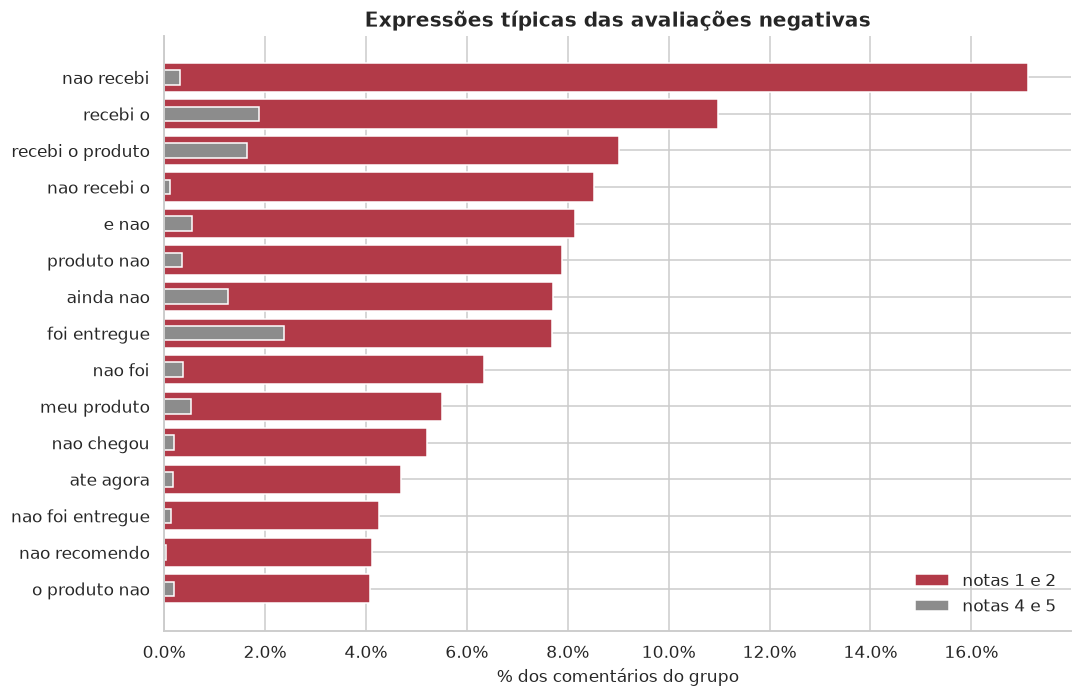

In [15]:
fig, ax = plt.subplots(figsize=(10, 6.5))
top = ng_neg.head(15)[::-1]
ax.barh(top["ngrama"], top["pct_neg"], color=RED, label="notas 1 e 2")
ax.barh(top["ngrama"], top["pct_pos"], color=GRAY, label="notas 4 e 5", height=0.4)
ax.set(title="Expressões típicas das avaliações negativas", xlabel="% dos comentários do grupo")
fmt_pct(ax, "x", 1)
ax.legend(loc="lower right")
save(fig, "02_expressoes_negativas");

"Não recebi" está em 17% dos comentários negativos e em 0,3% dos positivos. Com "ainda não", "não chegou", "não foi entregue", "até agora" e "estou aguardando", a maior parte das expressões negativas mais frequentes fala de pedido que não chegou; "não recomendo" aparece em 4% dos comentários negativos. Do lado positivo, "antes do prazo" está em 14% dos comentários, seguido de "muito bom", "chegou antes" e "super recomendo".

### HT2. Falar de entrega não é reclamar de entrega

Se o vocabulário de entrega aparece tanto em elogios quanto em reclamações, uma busca só por semelhança de texto para "reclamações de entrega" vai trazer elogios. Teste: proporção de comentários que usam vocabulário de entrega (entreg-, prazo, cheg-, receb-, correio, atras-, transportadora, frete) por situação da entrega, e a nota desses comentários.

In [16]:
VOCAB_ENTREGA = re.compile(r"\b(?:entreg\w*|prazo\w*|cheg\w*|receb\w*|correio\w*|atras\w*|transportador\w*|frete\w*)\b")
docs["fala_de_entrega"] = docs["text_norm"].str.contains(VOCAB_ENTREGA)
tab = docs.groupby("delivery_status").agg(
    documentos=("review_id", "size"),
    pct_fala_entrega=("fala_de_entrega", lambda s: 100 * s.mean()),
    nota_media=("review_score", "mean"),
).round(1).loc[["no prazo", "atrasada", "nao entregue", "cancelada"]]
chi, p, *_ = stats.chi2_contingency(pd.crosstab(docs["delivery_status"], docs["fala_de_entrega"]))
print(f"qui-quadrado = {chi:,.0f}, p = {p:.1e}")
tab

qui-quadrado = 1,344, p = 3.9e-291


,documentos,pct_fala_entrega,nota_media
delivery_status,,,
no prazo,36391,49.7,4.0
atrasada,3814,77.6,1.9
nao entregue,1072,76.7,1.6
cancelada,816,61.4,1.5


In [17]:
no_prazo_entrega = docs[(docs["delivery_status"] == "no prazo") & docs["fala_de_entrega"]]
print(f"comentários de pedidos no prazo que falam de entrega: {len(no_prazo_entrega):,}".replace(",", "."))
print((100 * no_prazo_entrega["review_score"].value_counts(normalize=True).sort_index()).round(1).to_string())
todos_entrega = docs[docs["fala_de_entrega"]]
print(f"\nde todos os comentários que falam de entrega, {100 * (todos_entrega['review_score'] >= 4).mean():.0f}% têm nota 4 ou 5")

comentários de pedidos no prazo que falam de entrega: 18.104
review_score
1    15.6
2     4.8
3     8.3
4    14.8
5    56.5

de todos os comentários que falam de entrega, 60% têm nota 4 ou 5


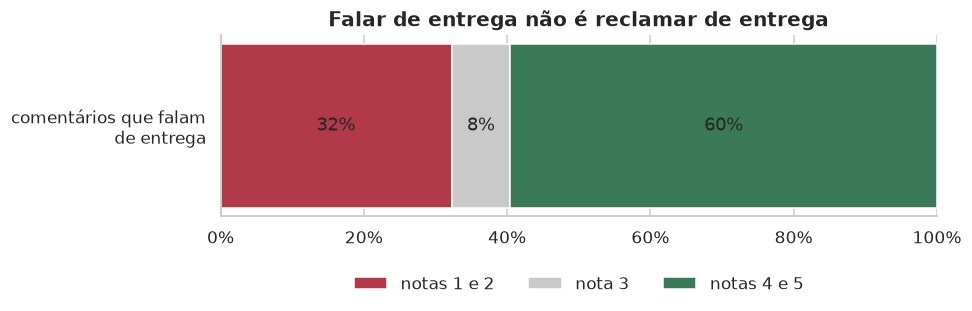

In [18]:
tab_plot = docs.assign(grupo=np.where(docs["review_score"] <= 2, "notas 1 e 2",
                                       np.where(docs["review_score"] >= 4, "notas 4 e 5", "nota 3")))
share = (100 * tab_plot[tab_plot["fala_de_entrega"]]["grupo"].value_counts(normalize=True)).reindex(
    ["notas 1 e 2", "nota 3", "notas 4 e 5"])
fig, ax = plt.subplots(figsize=(9, 3.2))
left = 0
for g, cor in zip(share.index, [RED, "#c9c9c9", GREEN]):
    ax.barh(["comentários que falam\nde entrega"], [share[g]], left=left, color=cor, label=g)
    ax.text(left + share[g] / 2, 0, f"{share[g]:.0f}%", ha="center", va="center", fontsize=12)
    left += share[g]
ax.set(title="Falar de entrega não é reclamar de entrega", xlim=(0, 100))
fmt_pct(ax, "x")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.25))
save(fig, "02_entrega_elogio_e_reclamacao");

**HT2 confirmada.** O vocabulário de entrega aparece em 78% dos comentários de pedidos atrasados, mas também em 50% dos entregues no prazo, e 60% de todos os comentários que falam de entrega têm nota 4 ou 5. A diferença entre situações é significativa (qui-quadrado = 1.344), mas o ponto prático é outro: entre os 18.104 comentários de pedidos no prazo que falam de entrega, 71% têm nota 4 ou 5.

**Decisão D09 (filtros por metadado):** uma pergunta sobre reclamações de entrega precisa restringir a busca às notas baixas ou aos pedidos atrasados e não recebidos, conforme o caso. Sem o filtro, a busca encontra o assunto certo com o sinal trocado.

### HT3. O mesmo problema é escrito de formas diferentes

Para "pedido não recebido" existe um grupo definido só por metadado: pedidos não entregues, cancelados ou cujo cliente respondeu antes de receber (D19, do notebook 01). Se a maioria desses clientes não usar a palavra "receber", a busca lexical por "não recebi" perde a maior parte das evidências.

In [19]:
nao_recebeu = docs[(docs["delivery_status"].isin(["nao entregue", "cancelada"])) | docs["answered_before_delivery"]]
LITERAL = re.compile(r"\bnao (?:recebi|recebeu|recebemos|foi entregue)\b")
usa_literal = nao_recebeu["text_norm"].str.contains(LITERAL)
usa_receb = nao_recebeu["text_norm"].str.contains(r"\breceb")
print(f"avaliações do grupo 'não recebeu' (metadado): {len(nao_recebeu):,}".replace(",", "."))
print(f"  usam 'não recebi / recebeu / foi entregue': {100 * usa_literal.mean():.0f}%")
print(f"  usam qualquer forma de 'receber': {100 * usa_receb.mean():.0f}%")
nao_recebeu.loc[~usa_receb, "text_clean"].sample(10, random_state=11).to_frame("comentários sem a palavra 'receber'")

avaliações do grupo 'não recebeu' (metadado): 4.982
  usam 'não recebi / recebeu / foi entregue': 35%
  usam qualquer forma de 'receber': 37%


,comentários sem a palavra 'receber'
31682,Ainda aguardando o produto
6513,"Tudo certo com a loja, mas 1 mês esperando os COrreios entregarem."
3739,simplesmente entregaram nos correios para eu ir retirar e nem me informaram disso. resultado? o produto foi devolvid...
32750,Mercadoria não chegou! Quero meu dinheiro de volta.
10973,"A mercadoria ainda não chegou um absurdo, eu fiz uma compra no mercado livre saindo de são paulo mesmo lugar desse p..."
39189,estou pagando pelo produto e ate exato momento ele não chegou a minha residencia.
13422,"O produto era pra ser entregue dia 19/02. E até agora não tive nenhuma satisfação sobre o produto, ou sobre a entreg..."
24476,"A loja sempre entregou em dia, mas dessa vez não.Estou aguardando."
3578,Apesar de fazer o pedido pelo telefone o prazo dado não foi cumprido.
29166,Meu produto foi devolvido pelo os correio e a loja não me passou nenhuma informação até hoje. Estou aguardando! Vou ...


**HT3 confirmada.** Dos 4.982 comentários do grupo, só 35% usam "não recebi", "não recebeu" ou "não foi entregue", e 37% usam alguma forma de "receber". Os outros 63% escrevem "ainda aguardando", "não chegou", "esperando os Correios", "o prazo não foi cumprido", "foi devolvido".

**Decisão D07 (busca híbrida):** a busca lexical (BM25) é precisa quando o cliente usa a palavra da pergunta; a semântica cobre as paráfrases. As duas entram, combinadas por Reciprocal Rank Fusion, e a ablação do notebook 05 mede quanto cada uma contribui.

## 4. O que fica decidido

O registro completo, com a evidência de cada decisão, está em `docs/decisoes_analiticas.md`.

| Decisão | Evidência |
|---|---|
| D01 um documento por avaliação, sem fragmentação | percentil 99 de 57 tokens contra limite de 128; um único documento acima, por pontuação repetida |
| D02 avaliações sem texto ficam fora do índice e dentro das estatísticas | 56.040 avaliações só com nota (notebook 01); 277 sem palavra útil depois da limpeza |
| D03 texto original para exibição, limpo para embeddings e contexto, normalizado para deduplicação e BM25 | quebras de linha, emojis e pontuação repetida nos comentários |
| D04 deduplicação com contagem e filtro por avaliação | 8.230 avaliações em 1.026 textos repetidos; 93% desses grupos com mais de uma categoria |
| D07 busca híbrida lexical e semântica | 63% do grupo "não recebeu" não usa a palavra "receber" |
| D09 filtros por metadado | 60% dos comentários que falam de entrega têm nota 4 ou 5 |
| D21 títulos sem comentário entram no índice | 1.729 avaliações, quase todas elogios genéricos que se juntam aos grupos repetidos |
| D22 negações mantidas no índice lexical | "não" é o termo que mais separa notas baixas e altas (61% contra 7% dos comentários) |

O próximo passo é construir os índices: BM25 sobre os radicais (`src/indexing/lexical.py`) e o índice vetorial sobre os embeddings (notebook 03).